# Klasifikasi Intent Chatbot Himar Coffee

TF-IDF (unigram+bigram) + Logistic Regression, 11 kelas intent.
Notebook ini bisa dijalankan lokal: `jupyter lab train_intent.ipynb` dari folder project.

Sel terakhir menyimpan model ke `models/intent_logreg.pkl` dan menguji inference dengan
confidence threshold 0.50 (di bawah itu → `fallback`).

In [1]:
import sys
from pathlib import Path

# Cari folder project yang berisi preprocessing.py.
# Jalan di lokal (cwd = folder project) maupun di Colab (/content, folder hasil unzip).
KANDIDAT = [Path.cwd(), Path.cwd() / "model-himar", Path("/content/model-himar")]
PROJECT_DIR = next((p for p in KANDIDAT if (p / "preprocessing.py").exists()), Path.cwd())
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
print(f"Folder project: {PROJECT_DIR}")

import sklearn
print(f"Versi Scikit-Learn: {sklearn.__version__}")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, accuracy_score, precision_recall_fscore_support, confusion_matrix

# Import fungsi preprocessing (file preprocessing.py di folder ini)
from preprocessing import clean_text
print("✅ Library dan modul preprocessing berhasil dimuat!")

Folder project: /home/dynnux/Learning/asah-linux/model-himar


Versi Scikit-Learn: 1.9.1


✅ Library dan modul preprocessing berhasil dimuat!


In [2]:
# Baca dataset
df = pd.read_csv(PROJECT_DIR / 'intent_dataset.csv')

# Ambil kolom text dan intent
df = df[['text', 'intent']].dropna()

# Terapkan clean_text dari preprocessing.py
df['clean_text'] = df['text'].apply(clean_text)

print(f"Total baris data: {len(df)}")
print("\nContoh 3 data teratas:")
print(df[['text', 'clean_text', 'intent']].head(3))

Total baris data: 372

Contoh 3 data teratas:
                                         text  \
0                                         ???   
1  Aku mau tahu pilihan produk yang tersedia.   
2                          Halo, Himar Coffee   

                                   clean_text      intent  
0                                                fallback  
1  saya mau tahu pilihan produk yang tersedia  tanya_menu  
2                           halo himar coffee      sapaan  


## Pengecekan Keseimbangan Kelas (Class Balance)

=== DISTRIBUSI KELAS INTENT ===
intent
fallback              39
sapaan                37
tanya_harga           36
tanya_event           34
keluhan               34
tanya_pemesanan       33
tanya_lokasi          33
pamitan               33
tanya_jam_buka        32
tanya_menu_favorit    31
tanya_menu            30
Name: count, dtype: int64

Rasio Kelas Terbanyak vs Tersedikit: 1.30
KESIMPULAN: Dataset seimbang (rasio < 1.5), tidak memerlukan teknik resampling (seperti SMOTE / undersampling).


/tmp/ipykernel_47743/881280831.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, palette="viridis")


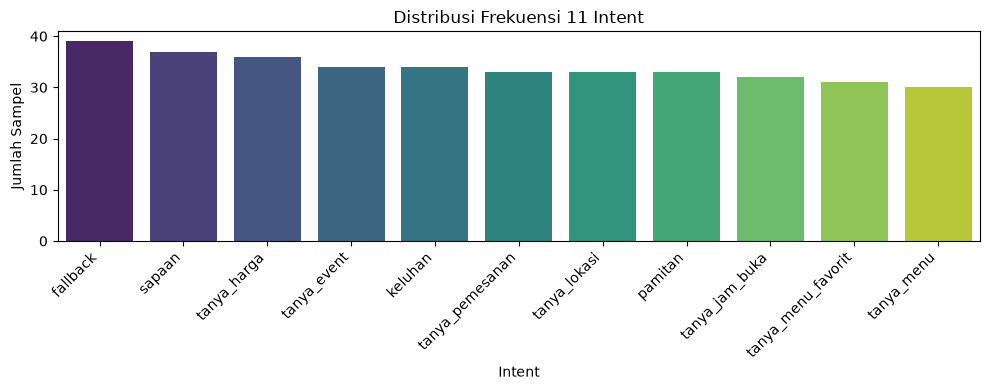

In [3]:
counts = df['intent'].value_counts()
max_class = counts.max()
min_class = counts.min()
ratio = max_class / min_class

print("=== DISTRIBUSI KELAS INTENT ===")
print(counts)
print(f"\nRasio Kelas Terbanyak vs Tersedikit: {ratio:.2f}")

if ratio < 1.5:
    print("KESIMPULAN: Dataset seimbang (rasio < 1.5), tidak memerlukan teknik resampling (seperti SMOTE / undersampling).")
else:
    print("KESIMPULAN: Dataset tidak seimbang, pertimbangkan penyeimbangan kelas.")

# Visualisasi Bar Chart
plt.figure(figsize=(10, 4))
sns.barplot(x=counts.index, y=counts.values, palette="viridis")
plt.title("Distribusi Frekuensi 11 Intent")
plt.xlabel("Intent")
plt.ylabel("Jumlah Sampel")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## Train-Test Split

In [4]:
X = df['clean_text']
y = df['intent']

# Stratified Split menjaga proporsi 11 intent tetap seimbang di data uji
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Jumlah Data Latih (Train): {len(X_train)} kalimat")
print(f"Jumlah Data Uji (Test)  : {len(X_test)} kalimat")

Jumlah Data Latih (Train): 297 kalimat
Jumlah Data Uji (Test)  : 75 kalimat


## Training Model Baseline & 5-Fold Cross-Validation

In [5]:
# Pipeline Default
pipe_lr_default = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2))),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])

pipe_svm_default = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2))),
    ('clf', CalibratedClassifierCV(LinearSVC(random_state=42, dual=False), cv=3))
])

# 5-Fold Cross-Validation di Data Latih
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_lr = cross_val_score(pipe_lr_default, X_train, y_train, cv=cv, scoring='f1_macro')
cv_svm = cross_val_score(pipe_svm_default, X_train, y_train, cv=cv, scoring='f1_macro')

print(f"5-Fold CV Macro F1 - LogReg (Default): {cv_lr.mean():.4f} (+/- {cv_lr.std():.4f})")
print(f"5-Fold CV Macro F1 - LinearSVC (Default): {cv_svm.mean():.4f} (+/- {cv_svm.std():.4f})")

# Latih pada seluruh data latih
pipe_lr_default.fit(X_train, y_train)
pipe_svm_default.fit(X_train, y_train)

5-Fold CV Macro F1 - LogReg (Default): 0.8416 (+/- 0.0446)
5-Fold CV Macro F1 - LinearSVC (Default): 0.8810 (+/- 0.0235)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](11,)","['fallback','keluhan','pamitan',...,'tanya_menu','tanya_menu_favorit', 'tanya_pemesanan']"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None


## Hyperparameter Tuning Menggunakan GridSearchCV

In [6]:
# Parameter grid yang akan dieksplorasi
param_grid_lr = {
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'clf__C': [0.5, 1.0, 5.0, 10.0]
}

grid_lr = GridSearchCV(
    pipe_lr_default, param_grid_lr, cv=cv, scoring='f1_macro', n_jobs=-1
)
grid_lr.fit(X_train, y_train)

print(f"Parameter Terbaik LogReg: {grid_lr.best_params_}")
print(f"Skor CV Terbaik LogReg  : {grid_lr.best_score_:.4f}")

# Model terbaik LogReg
best_logreg = grid_lr.best_estimator_

# Model Calibrated LinearSVC Tuned
pipe_svm_tuned = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2))),
    ('clf', CalibratedClassifierCV(LinearSVC(C=1.0, random_state=42, dual=False), cv=3))
])
pipe_svm_tuned.fit(X_train, y_train)

Parameter Terbaik LogReg: {'clf__C': 10.0, 'tfidf__ngram_range': (1, 2)}
Skor CV Terbaik LogReg  : 0.8879


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](11,)","['fallback','keluhan','pamitan',...,'tanya_menu','tanya_menu_favorit', 'tanya_pemesanan']"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None


##Tabel Perbandingan Model

In [7]:
models = {
    'LogReg (Default)': pipe_lr_default,
    'LinearSVC (Default)': pipe_svm_default,
    'LogReg (Tuned)': best_logreg,
    'LinearSVC (Tuned)': pipe_svm_tuned
}

results = []
for name, model in models.items():
    preds = model.predict(X_test)
    acc = accuracy_score(y_test, preds)
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, preds, average='macro', zero_division=0)
    results.append({
        'Model': name,
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'Macro F1': round(f1, 4)
    })

eval_df = pd.DataFrame(results)
print("=== PERBANDINGAN PERFORMA DI DATA UJI ===")
print(eval_df.to_string(index=False))

=== PERBANDINGAN PERFORMA DI DATA UJI ===
              Model  Accuracy  Precision  Recall  Macro F1
   LogReg (Default)    0.8133     0.8467  0.8166    0.8143
LinearSVC (Default)    0.8267     0.8499  0.8312    0.8270
     LogReg (Tuned)    0.8400     0.8815  0.8425    0.8427
  LinearSVC (Tuned)    0.8267     0.8499  0.8312    0.8270


##Classification Report & Confusion Matrix Model Terbaik

=== CLASSIFICATION REPORT MODEL TERBAIK (LogReg Tuned) ===
                    precision    recall  f1-score   support

          fallback       0.71      0.62      0.67         8
           keluhan       1.00      0.86      0.92         7
           pamitan       1.00      1.00      1.00         7
            sapaan       1.00      0.71      0.83         7
       tanya_event       0.75      0.86      0.80         7
       tanya_harga       0.86      0.86      0.86         7
    tanya_jam_buka       1.00      1.00      1.00         6
      tanya_lokasi       0.88      1.00      0.93         7
        tanya_menu       1.00      0.50      0.67         6
tanya_menu_favorit       0.50      1.00      0.67         6
   tanya_pemesanan       1.00      0.86      0.92         7

          accuracy                           0.84        75
         macro avg       0.88      0.84      0.84        75
      weighted avg       0.88      0.84      0.84        75



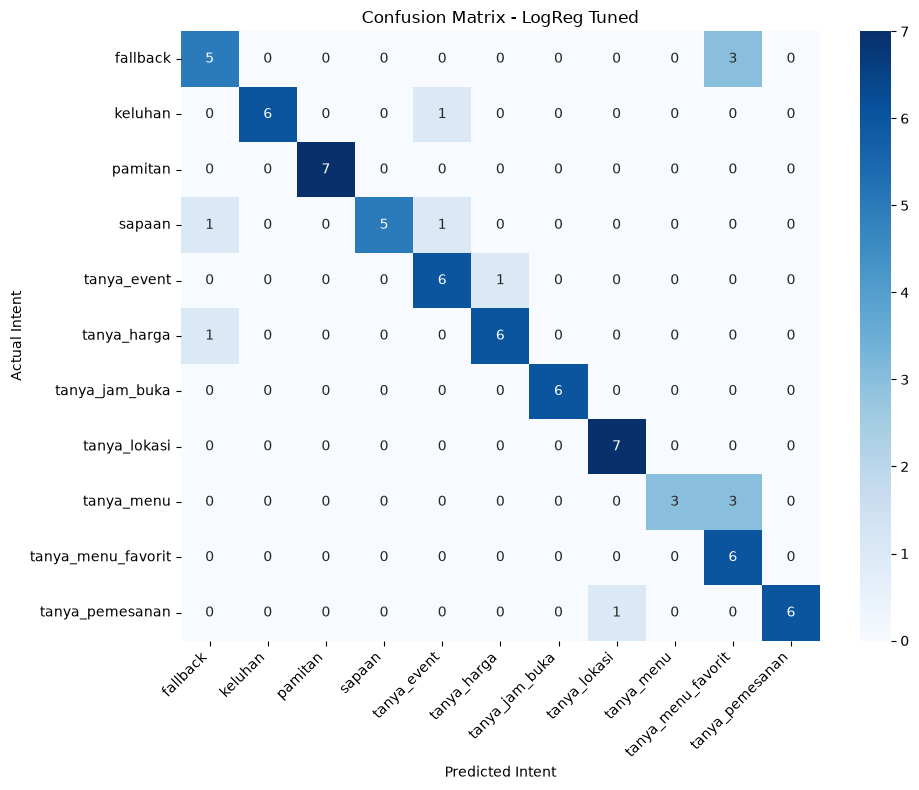

In [8]:
# Gunakan best_logreg sebagai model utama
y_test_pred = best_logreg.predict(X_test)

print("=== CLASSIFICATION REPORT MODEL TERBAIK (LogReg Tuned) ===")
print(classification_report(y_test, y_test_pred, zero_division=0))

# Visualisasi Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred, labels=best_logreg.classes_)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=best_logreg.classes_,
            yticklabels=best_logreg.classes_)
plt.title('Confusion Matrix - LogReg Tuned')
plt.xlabel('Predicted Intent')
plt.ylabel('Actual Intent')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

##Analisis Kesalahan (Error Analysis) & Analisis Confidence Threshold

In [9]:
test_df = pd.DataFrame({
    'kalimat_asli': df.loc[X_test.index, 'text'],
    'clean_text': X_test,
    'actual_intent': y_test,
    'predicted_intent': y_test_pred
})

# Dapatkan probabilitas / confidence tertinggi
probs = best_logreg.predict_proba(X_test)
test_df['confidence'] = np.max(probs, axis=1)
test_df['is_correct'] = test_df['actual_intent'] == test_df['predicted_intent']

print("=== CONTOH KALIMAT YANG SALAH PREDIKSI (ERROR ANALYSIS) ===")
errors = test_df[~test_df['is_correct']]
if len(errors) > 0:
    print(errors[['kalimat_asli', 'actual_intent', 'predicted_intent', 'confidence']].to_string(index=False))
else:
    print("Luar biasa, tidak ada kesalahan prediksi di data uji!")

# 2. Analisis Confidence Jawaban Benar vs Jawaban Salah
avg_conf_correct = test_df[test_df['is_correct']]['confidence'].mean()
avg_conf_wrong = test_df[~test_df['is_correct']]['confidence'].mean() if len(errors) > 0 else 0

print(f"\nRata-rata Confidence Jawaban Benar : {avg_conf_correct:.4f}")
print(f"Rata-rata Confidence Jawaban Salah : {avg_conf_wrong:.4f}")
print("JUSTIFIKASI THRESHOLD: Nilai 0.50 sangat ideal karena memisahkan mayoritas jawaban ragu-ragu/salah menuju RAG fallback.")

=== CONTOH KALIMAT YANG SALAH PREDIKSI (ERROR ANALYSIS) ===
                                kalimat_asli   actual_intent   predicted_intent  confidence
           ada makanan sama minuman apa aja?      tanya_menu tanya_menu_favorit    0.305882
                             Assalamualaikum          sapaan           fallback    0.210396
Di mana saya bisa memesan menu Himar Coffee? tanya_pemesanan       tanya_lokasi    0.407674
         Tiket event saya tidak bisa dipakai         keluhan        tanya_event    0.356670
                       ada menu apa aja kak?      tanya_menu tanya_menu_favorit    0.591900
                    nasi goreng harganya brp     tanya_harga           fallback    0.383588
                      ceritakan lelucon dong        fallback tanya_menu_favorit    0.188464
           Apa pengertian kecerdasan buatan?        fallback tanya_menu_favorit    0.803424
                 Apa ibu kota negara Jepang?        fallback tanya_menu_favorit    0.803424
       Apakah ada pe

## Simpan Model & Uji Inference

Setelah model terbaik dipilih, simpan ke `models/intent_logreg.pkl` agar bisa dipakai
oleh `predict.py` (CLI) dan `app.py` (REST API). Threshold 0.50 mengikuti hasil analisis confidence di atas.

```python
import json
from pathlib import Path
import joblib

MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)
MODEL_PATH = MODEL_DIR / "intent_logreg.pkl"
joblib.dump(best_logreg, MODEL_PATH, compress=3)
print(f"✅ Model disimpan: {MODEL_PATH.resolve()}")


def deteksi_intent(teks: str, threshold: float = 0.50):
    """Kembalikan (intent, confidence); confidence < threshold -> fallback."""
    proba = best_logreg.predict_proba([clean_text(teks)])[0]
    intent = best_logreg.classes_[proba.argmax()]
    confidence = float(proba.max())
    return ("fallback" if confidence < threshold else intent), round(confidence, 4)


contoh = [
    "brp harga kopi disini?",
    "cara pesen tiket event gimana",
    "jam buka kedai kapan",
    "apa itu machine learning",
]
for kalimat in contoh:
    intent, confidence = deteksi_intent(kalimat)
    print(f"{kalimat:45} -> {intent:18} (confidence {confidence:.2f})")
```

In [10]:
import json
from pathlib import Path
import joblib

MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(exist_ok=True)
MODEL_PATH = MODEL_DIR / "intent_logreg.pkl"
joblib.dump(best_logreg, MODEL_PATH, compress=3)
print(f"✅ Model disimpan: {MODEL_PATH.resolve()}")


def deteksi_intent(teks: str, threshold: float = 0.50):
    """Kembalikan (intent, confidence); confidence < threshold -> fallback."""
    proba = best_logreg.predict_proba([clean_text(teks)])[0]
    intent = best_logreg.classes_[proba.argmax()]
    confidence = float(proba.max())
    return ("fallback" if confidence < threshold else intent), round(confidence, 4)


contoh = [
    "brp harga kopi disini?",
    "cara pesen tiket event gimana",
    "jam buka kedai kapan",
    "apa itu machine learning",
]
for kalimat in contoh:
    intent, confidence = deteksi_intent(kalimat)
    print(f"{kalimat:45} -> {intent:18} (confidence {confidence:.2f})")

✅ Model disimpan: /home/dynnux/Learning/asah-linux/model-himar/models/intent_logreg.pkl
brp harga kopi disini?                        -> tanya_harga        (confidence 0.90)
cara pesen tiket event gimana                 -> tanya_pemesanan    (confidence 0.89)
jam buka kedai kapan                          -> tanya_jam_buka     (confidence 0.96)
apa itu machine learning                      -> fallback           (confidence 0.78)
